# Results

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, accuracy_score, auc, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.svm import SVC
from toolbox import Masking
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.processing import augment_patient_and_cat_specific
from toolbox.results import Results_data_loading, ResultsROCAUC
from toolbox.visualization import plot_confusion_matrix_custom

warnings.filterwarnings("ignore")
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
mask.prints = False

In [2]:
# define number of group splits
cv = GroupKFold(n_splits=5)
parameter_type = "tuned"  # "default"
results_path = "results"

## Task 1 : healthy versus cancer


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{'Cancer': [1, 0], 'Healthy': [0, 1]}


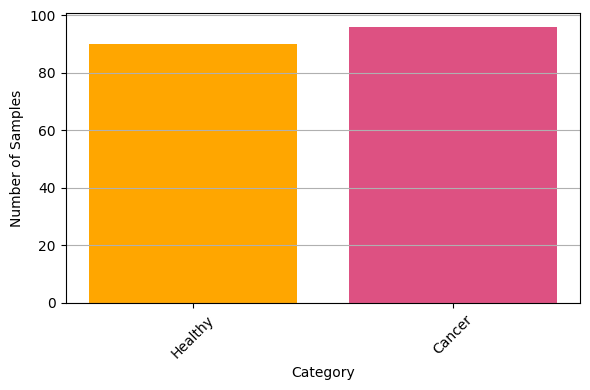


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)
6.02657413482666


In [3]:
class_task = "healthy_vs_cancer"

n_folds = 5  # number of iterations inside each LPOCV
output_prints = False
start = time.time()
Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)
end = time.time()
print(end - start)  # time in seconds

**SVM**

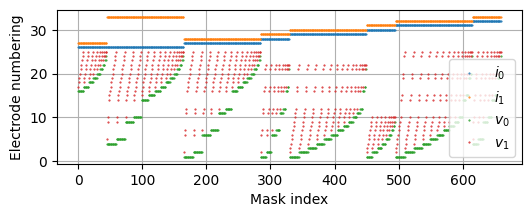

(186, 3300)


In [4]:
Msel = "Adj. far"  # Adj. far | Skip1 far | Opp. medium
Fsel = "Top 5"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="linear", C=0.001, probability=True)

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [8]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.8279569892473119


In [9]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.9003472222222222


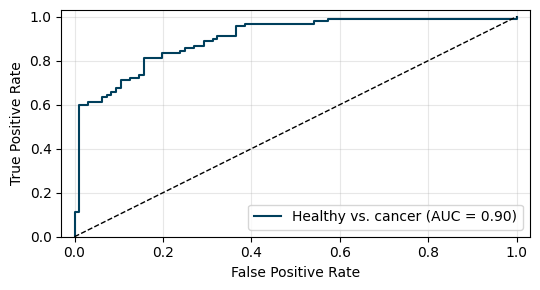

In [10]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

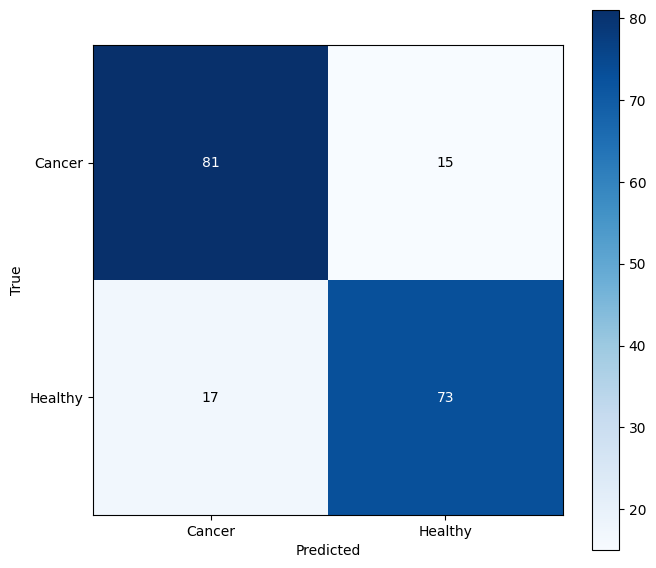

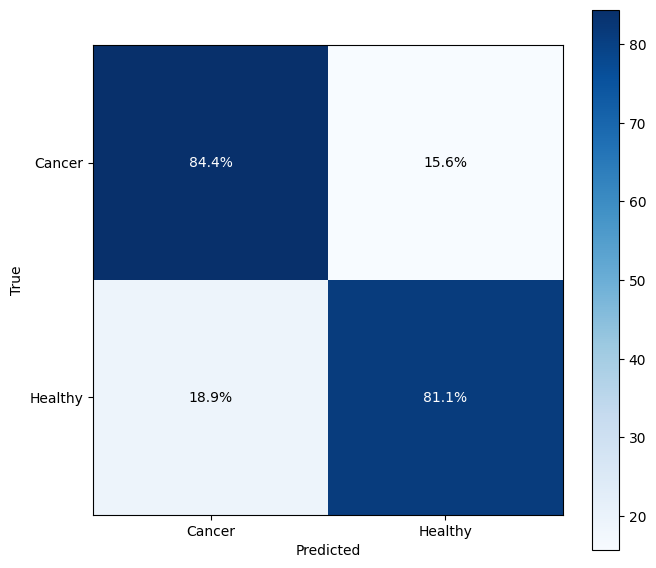

In [11]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_cmp.pdf",
)

**RF**

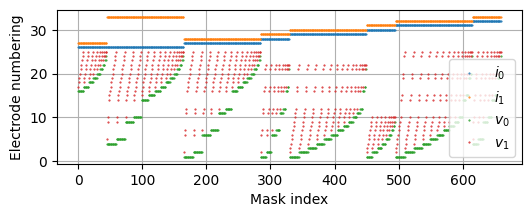

(186, 3960)


In [27]:
Msel = "Adj. far"  # Adj. far | Skip1 far | Opp. medium
Fsel = "Top 6"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=500,
        max_depth=510,
        max_features="sqrt",
        min_samples_split=5,
        min_samples_leaf=1,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [28]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7956989247311828


In [29]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.8994212962962963


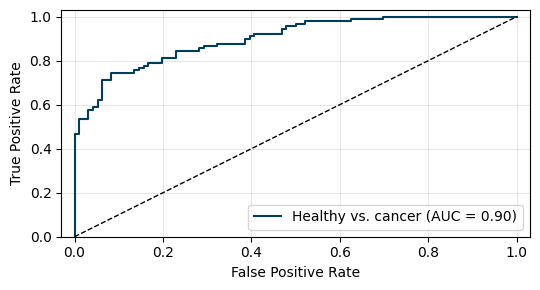

In [30]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF.pdf",
)

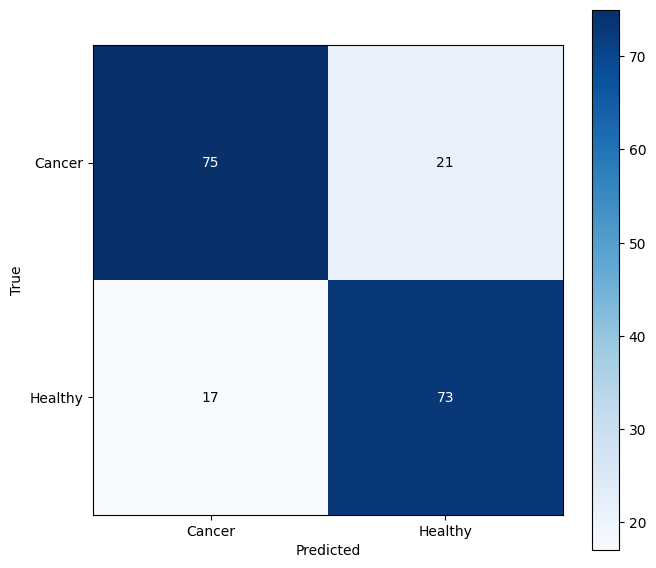

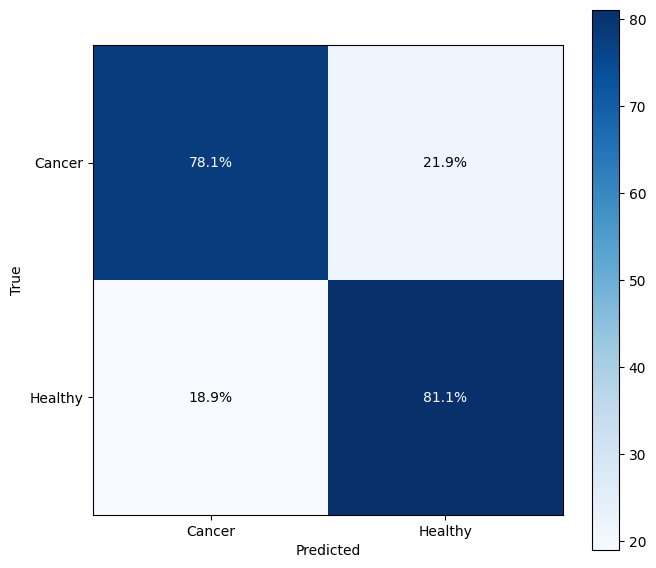

In [31]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_cmp.pdf",
)

**LR**

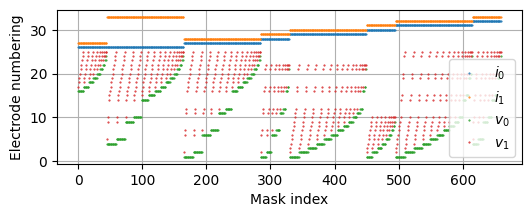

(186, 4620)


In [32]:
Msel = "Adj. far"  # Adj. far | Skip1 far | Opp. medium
Fsel = "Top 7"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [33]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.8064516129032258


In [34]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.890625


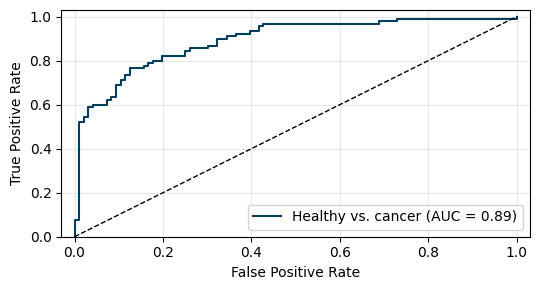

In [35]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR.pdf",
)

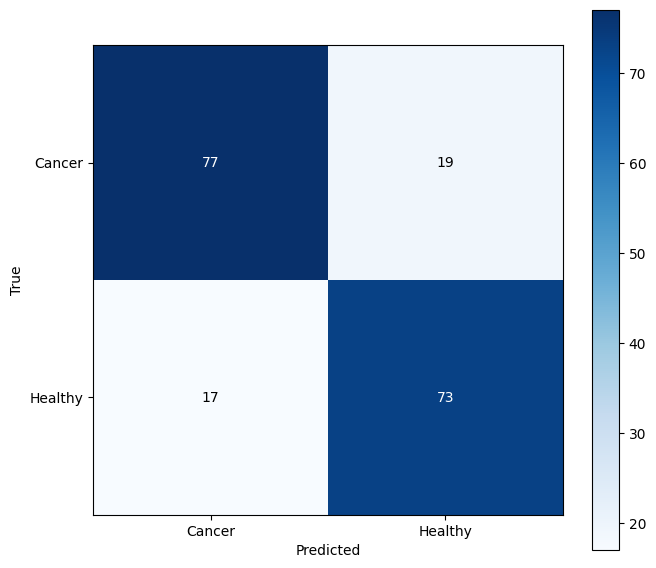

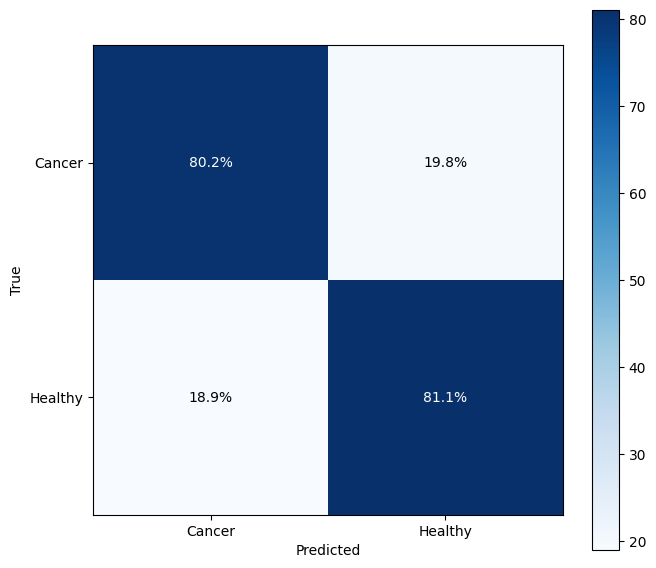

In [36]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_cmp.pdf",
)

## Task 2 : High risk vs. Low risk


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

High risk vs. Low risk

High risk: 125 entries
Low risk: 41 entries
Available cases: ['High risk' 'Low risk']
Coding: -> forward
{'High risk': [1, 0], 'Low risk': [0, 1]}


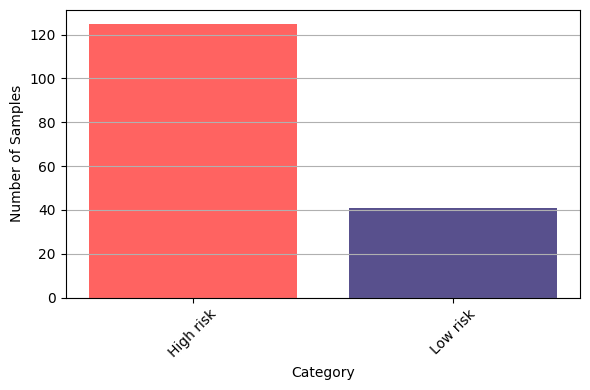


Inverse mapping: {(1, 0): 'High risk', (0, 1): 'Low risk'}
(166, 31, 7728) (166, 2) (166,)


In [37]:
class_task = "hr_vs_lr"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(class_task)

**SVM**

In [45]:
Mask_sel["Skip1 medium"] = "skip1_medium"

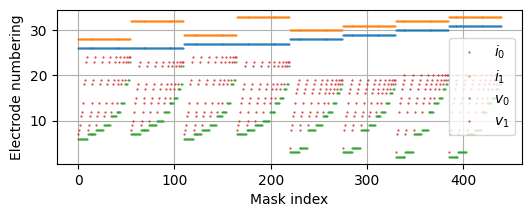

(166, 11880)


In [46]:
Msel = "Skip1 medium"  # Med. a+ ext. | Adj. close | Skip1 far
Fsel = "Top 27"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="rbf", C=100.0, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [47]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7349397590361446


In [48]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.751609756097561


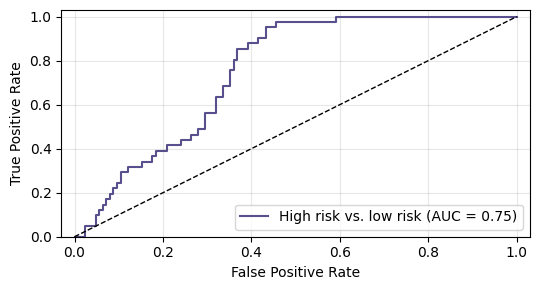

In [49]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

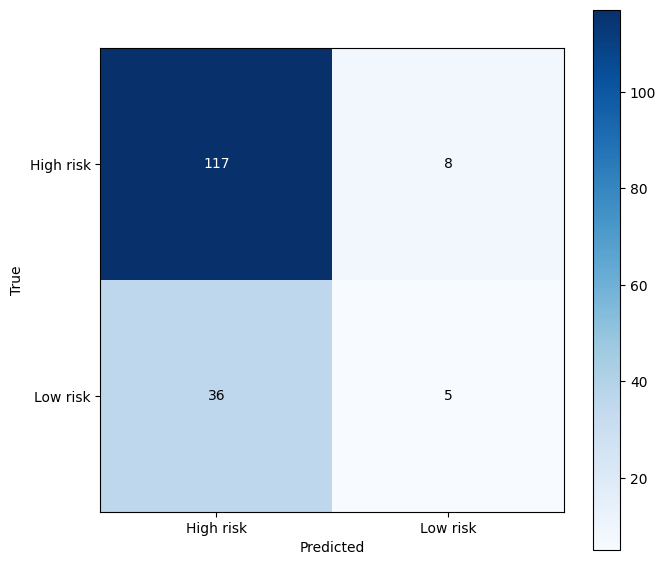

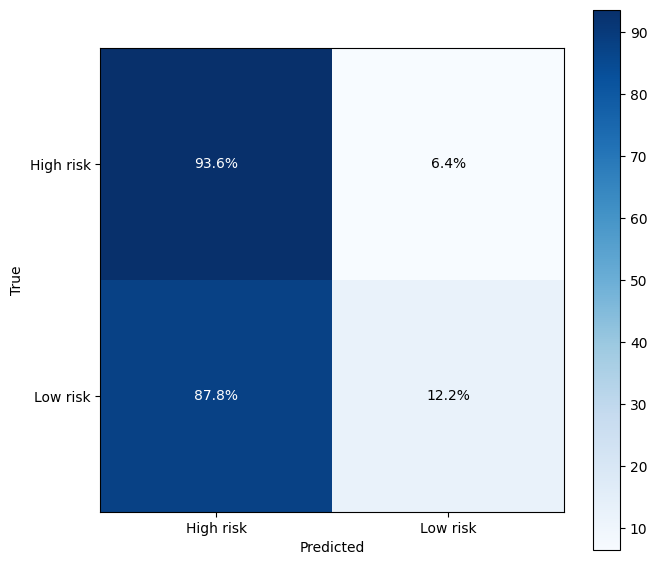

In [50]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["High risk", "Low risk"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["High risk", "Low risk"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_cmp.pdf",
)

**RF**

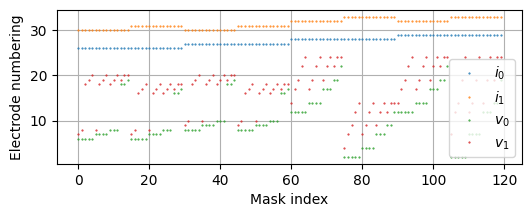

(166, 360)


In [79]:
Msel = "Med. a+ ext."  # Med. a+ ext. | Adj. close | Skip1 far
Fsel = "Top 3"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=4,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)
# select freq and IIVV and shape data
X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [89]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7650602409638554


In [90]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.726439024390244


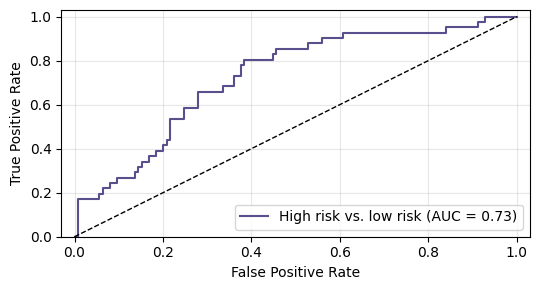

In [91]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF.pdf",
)

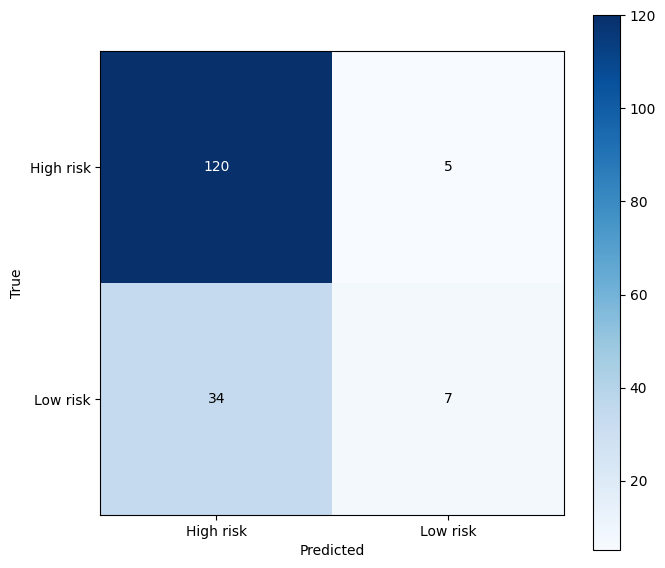

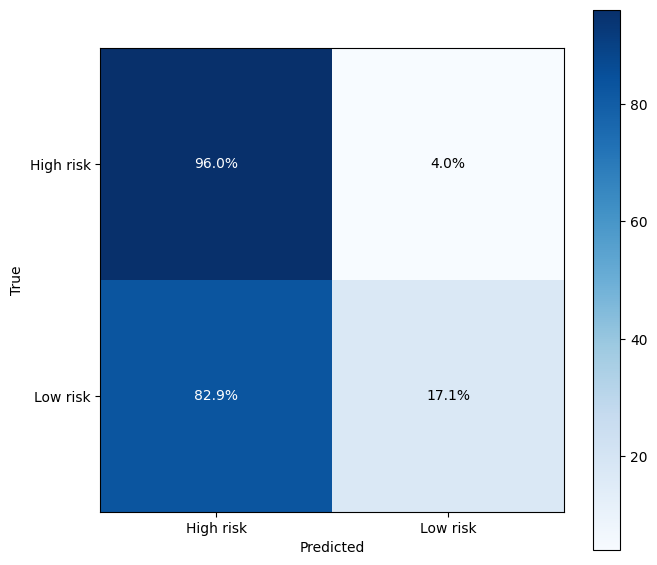

In [92]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["High risk", "Low risk"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["High risk", "Low risk"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_cmp.pdf",
)

**LR**

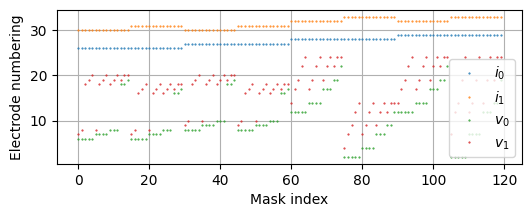

(166, 3600)


In [106]:
Msel = "Med. a+ ext."
Fsel = "Top 30"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=100)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [107]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.7108433734939759


In [108]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

AUC = 0.7012682926829269


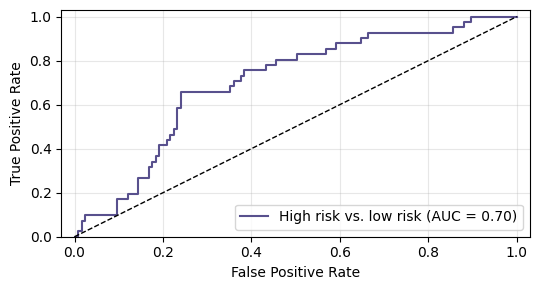

In [109]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR.pdf",
)

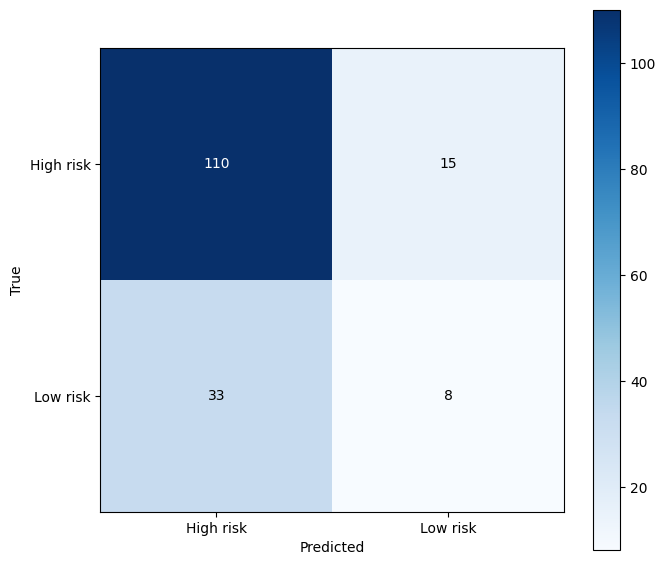

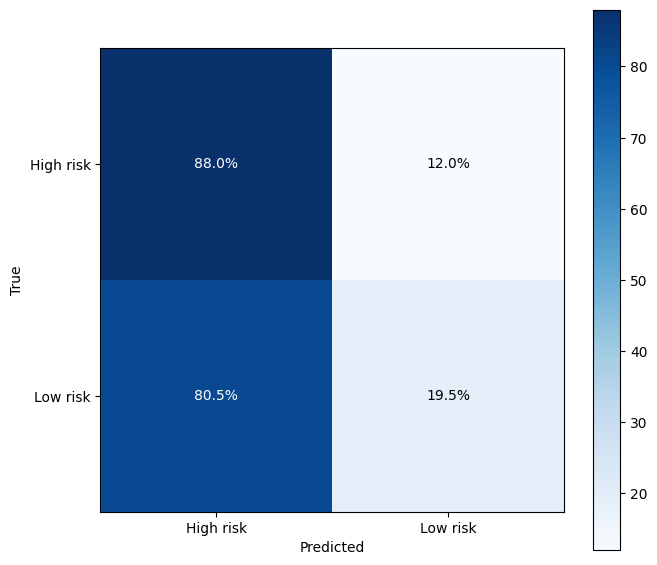

In [110]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["High risk", "Low risk"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["High risk", "Low risk"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_cmp.pdf",
)

In [111]:
X_train.shape

(133, 3600)

## Task 3: Multiclass


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

MC

Healthy: 90 entries
Cancer: 96 entries
High-grade dysplasia: 29 entries
Non-malignant: 41 entries
Available cases: ['Cancer' 'Healthy' 'High-grade dysplasia' 'Non-malignant']
Coding: -> forward
{'Cancer': [1, 0, 0, 0], 'Healthy': [0, 1, 0, 0], 'High-grade dysplasia': [0, 0, 1, 0], 'Non-malignant': [0, 0, 0, 1]}


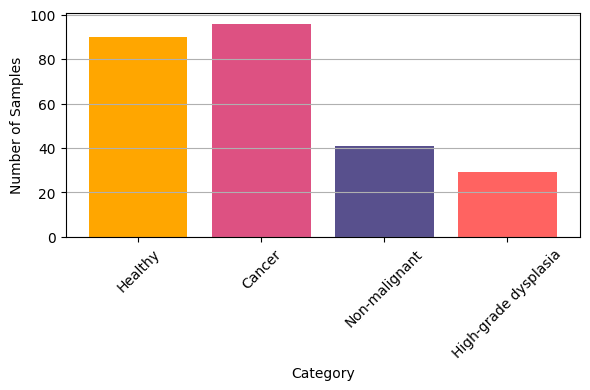


Inverse mapping: {(1, 0, 0, 0): 'Cancer', (0, 1, 0, 0): 'Healthy', (0, 0, 1, 0): 'High-grade dysplasia', (0, 0, 0, 1): 'Non-malignant'}
(256, 31, 7728) (256, 4) (256,)


In [112]:
class_task = "MC"

Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False  # augmentation done after train test split
)

**SVM**

In [124]:
Mask_sel

{'Adj. far': 'adjacent_far', 'Skip1 far': 'skip1_far'}

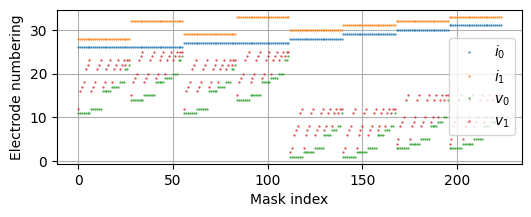

(256, 5152)


In [125]:
Msel = "Skip1 far"  # Adj. far
Fsel = "Top 23"
if parameter_type == "default":
    m = SVC(probability=True, random_state=0)
elif parameter_type == "tuned":
    m = SVC(kernel="poly", C=0.1, probability=True, random_state=0)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [126]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.6015625


In [127]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_SVM.npz",
    model_type="Tuned",
    model="SVM",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.7989400227864583


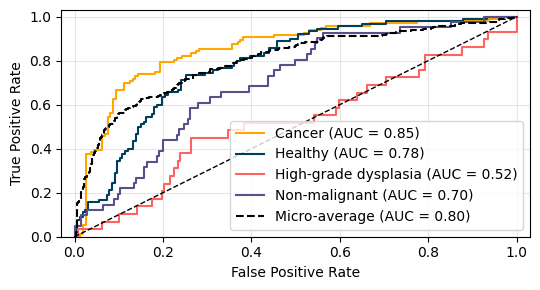

In [128]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM.pdf",
)

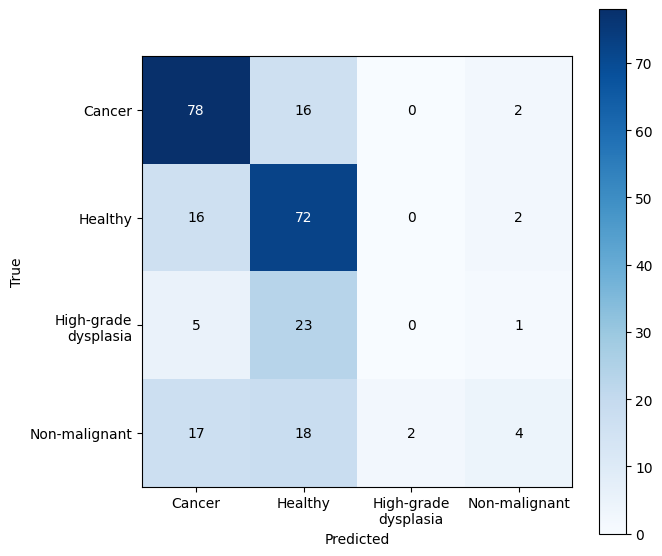

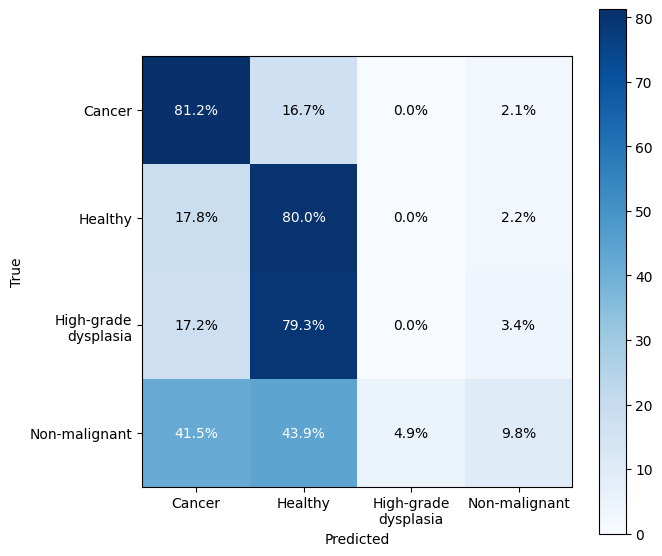

In [129]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_SVM_cmp.pdf",
)

**RF**

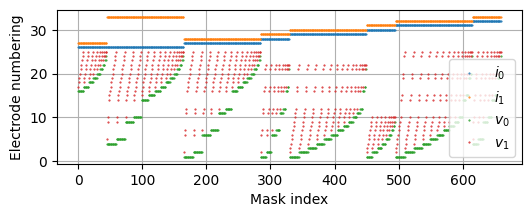

(256, 1980)


In [195]:
Msel = "Adj. far"  # Adj. far  Skip1 far
Fsel = "Top 3"
if parameter_type == "default":
    m = RandomForestClassifier()
elif parameter_type == "tuned":
    m = RandomForestClassifier(
        n_estimators=100,
        max_depth=510,
        max_features="sqrt",
        min_samples_split=2,
        min_samples_leaf=1,
    )

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [196]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.6171875


In [197]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_RF.npz",
    model_type="Tuned",
    model="RF",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.8163172403971354


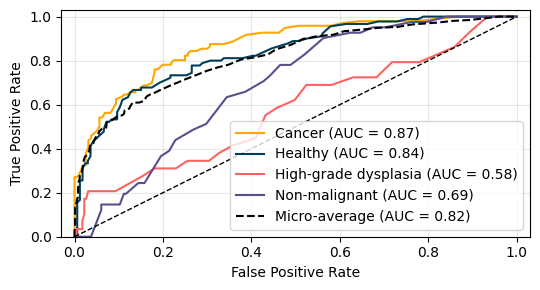

In [198]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_RF.pdf",
)

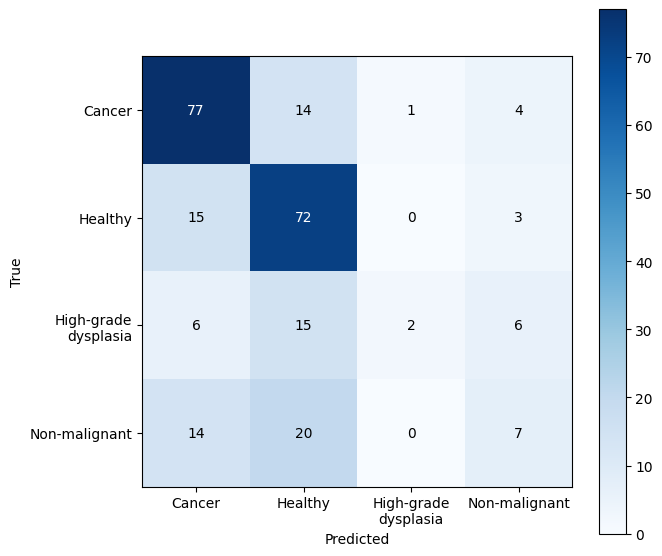

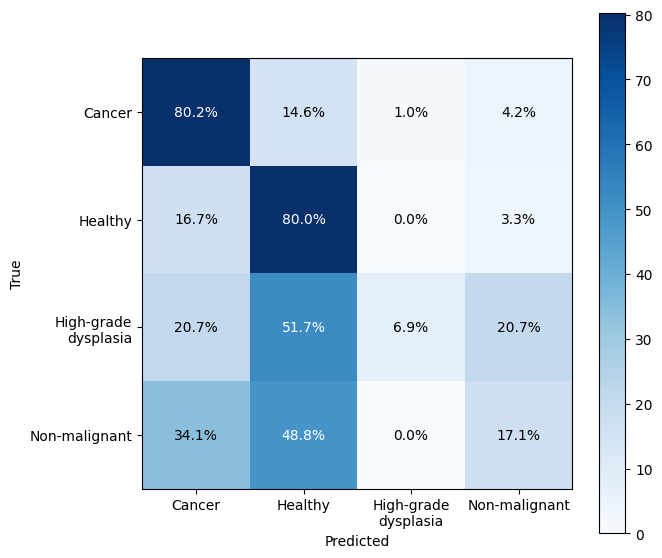

In [199]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_RF_cmp.pdf",
)

**LR**

In [238]:
Mask_sel["Skip1 medium"] = "skip1_medium"

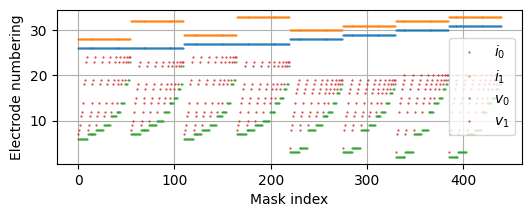

(256, 10120)


In [244]:
Msel = "Skip1 medium"  # Skip1 far | Adj. far
Fsel = "Top 23"
if parameter_type == "default":
    m = LogisticRegression()
elif parameter_type == "tuned":
    m = LogisticRegression(C=0.01, max_iter=1_000)

mask.IIVV_mask(Mask_sel[Msel], plot=True)

X_tmp = X[:, Freq_sel[Fsel], :]
X_tmp = X_tmp[:, :, mask.mask]
X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
print(X_tmp.shape)

In [245]:
y_true = []
y_score = []
y_pred = []

predict_durations = []
pred_test_samples = 0

# Cross-validation loop
for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
    X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
    y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]

    m.fit(X_train, y_train)

    t0 = time.time()
    probs = m.predict_proba(X_test)
    preds = np.argmax(probs, axis=1)
    t1 = time.time()

    pred_test_samples += len(test_idx)
    predict_durations.append((t1 - t0))

    y_true.extend(y_test)
    y_score.extend(probs)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_score = np.array(y_score)
y_pred = np.array(y_pred)

acc = accuracy_score(y_true, y_pred)
print("CV Accuracy:", acc)

CV Accuracy: 0.58984375


In [246]:
np.savez(
    f"{results_path}/timings_{parameter_type}_{class_task}_LR.npz",
    model_type="Tuned",
    model="LR",
    class_task=class_task,
    timings_CV_iter=predict_durations,
)

Micro-average AUC = 0.7783050537109374


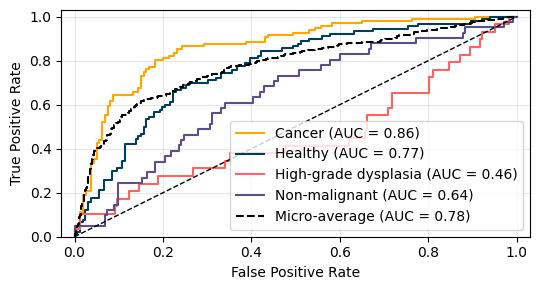

In [247]:
ResultsROCAUC(
    class_task,
    y_true,
    y_score,
    Y_labels,
    s_name=f"{results_path}/ROC_{parameter_type}_{class_task}_LR.pdf",
)

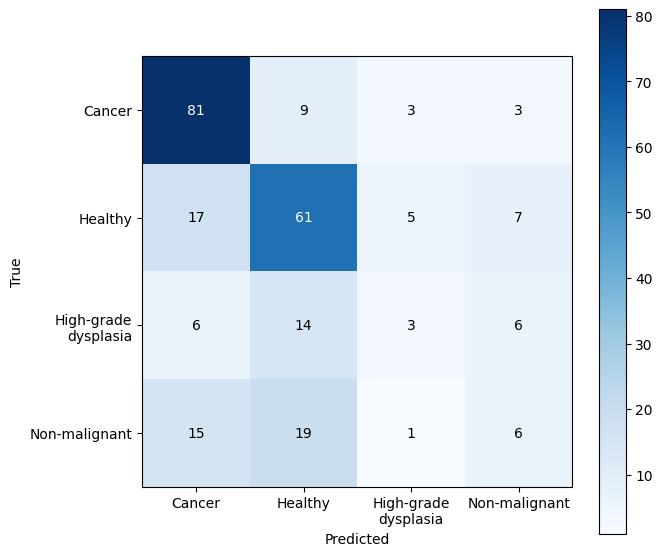

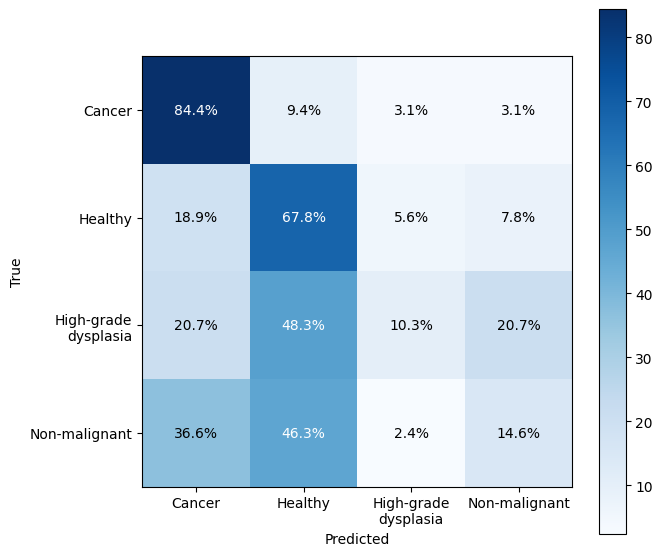

In [248]:
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=False,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_cm.pdf",
)
plot_confusion_matrix_custom(
    y_true,
    y_pred,
    class_names=["Cancer", "Healthy", "High-grade\ndysplasia", "Non-malignant"],
    normalize=True,
    path=f"{results_path}/ROC_{parameter_type}_{class_task}_LR_cmp.pdf",
)

___